In [1]:
import os

project_dir = "EEG-Analysis-Portfolio/Project_04_Automated_EEG_Report"

folders = [
    "notebooks",
    "results",
    "figures",
    "reports",
    "src"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

print("Project 04 目录创建成功：")

for folder in folders:
    print("✓", folder)

Project 04 目录创建成功：
✓ notebooks
✓ results
✓ figures
✓ reports
✓ src


In [2]:
import sys
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.executable)
print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nProject 04 环境检查完成")

Python: D:\Anaconda\envs\eeg\python.exe
MNE: 1.12.1
NumPy: 2.2.6
Pandas: 2.3.3

Project 04 环境检查完成


In [3]:
import os
import mne

# Project 03 数据文件的正确相对路径
data_path = (
    "../../Project_03_ICA_Artifact_Removal/"
    "results/EEG_ICA_cleaned_raw.fif"
)

# 先检查文件是否存在
print("当前工作目录：", os.getcwd())
print("数据文件是否存在：", os.path.exists(data_path))

if not os.path.exists(data_path):
    raise FileNotFoundError(f"找不到文件：{data_path}")

# 读取 EEG 数据
raw = mne.io.read_raw_fif(
    data_path,
    preload=True,
    verbose=False
)

print("\n===== EEG 数据读取成功 =====")
print("通道数量：", len(raw.ch_names))
print("采样率：", raw.info["sfreq"])
print("数据时长：", round(raw.times[-1], 2), "秒")
print("数据形状：", raw.get_data().shape)

当前工作目录： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\notebooks
数据文件是否存在： True

===== EEG 数据读取成功 =====
通道数量： 64
采样率： 160.0
数据时长： 124.99 秒
数据形状： (64, 20000)


In [4]:
import numpy as np
import pandas as pd

# 获取 EEG 数据，单位转换为 µV
eeg_data = raw.get_data(picks="eeg") * 1e6

# 基础质量指标
quality_report = {
    "通道数量": len(raw.copy().pick("eeg").ch_names),
    "采样率(Hz)": raw.info["sfreq"],
    "数据时长(秒)": raw.times[-1],
    "数据点数": eeg_data.shape[1],
    "NaN数量": np.isnan(eeg_data).sum(),
    "Inf数量": np.isinf(eeg_data).sum(),
    "整体最大振幅(µV)": np.max(np.abs(eeg_data)),
    "整体平均振幅(µV)": np.mean(np.abs(eeg_data))
}

quality_df = pd.DataFrame(
    list(quality_report.items()),
    columns=["质量指标", "结果"]
)

display(quality_df)

,质量指标,结果
0,通道数量,64.000000
1,采样率(Hz),160.000000
2,数据时长(秒),124.993750
3,数据点数,20000.000000
4,NaN数量,0.000000
5,Inf数量,0.000000
6,整体最大振幅(µV),205.642442
7,整体平均振幅(µV),17.063291


In [5]:
import pandas as pd
import numpy as np

channel_quality = pd.DataFrame({
    "通道": raw.copy().pick("eeg").ch_names,
    "平均绝对振幅(µV)": np.mean(np.abs(eeg_data), axis=1),
    "最大振幅(µV)": np.max(np.abs(eeg_data), axis=1),
    "标准差(µV)": np.std(eeg_data, axis=1)
})

channel_quality = channel_quality.sort_values(
    "最大振幅(µV)",
    ascending=False
)

display(channel_quality.head(15).round(2))

,通道,平均绝对振幅(µV),最大振幅(µV),标准差(µV)
62,O2,26.29,205.64,33.38
24,AF7,21.58,201.44,28.12
29,F7,19.60,198.99,25.48
25,AF3,20.93,187.33,27.24
22,Fpz,20.37,181.57,26.25
21,Fp1,21.44,167.31,27.70
59,PO8,23.32,163.99,29.77
23,Fp2,20.52,162.20,26.50
28,AF8,19.51,161.21,25.23
60,O1,22.36,160.22,28.59


In [6]:
import numpy as np
import pandas as pd

top_channels = channel_quality.head(5)["通道"].tolist()

rows = []

for ch in top_channels:

    data = raw.get_data(picks=[ch])[0] * 1e6

    max_index = np.argmax(np.abs(data))

    rows.append({
        "通道": ch,
        "最大振幅(µV)": np.max(np.abs(data)),
        "发生时间(秒)": raw.times[max_index],
        "信号方向": "正向" if data[max_index] > 0 else "负向"
    })

extreme_events = pd.DataFrame(rows)

display(extreme_events.round(2))

,通道,最大振幅(µV),发生时间(秒),信号方向
0,O2,205.64,98.54,负向
1,AF7,201.44,44.64,正向
2,F7,198.99,44.64,正向
3,AF3,187.33,44.64,正向
4,Fpz,181.57,70.91,负向


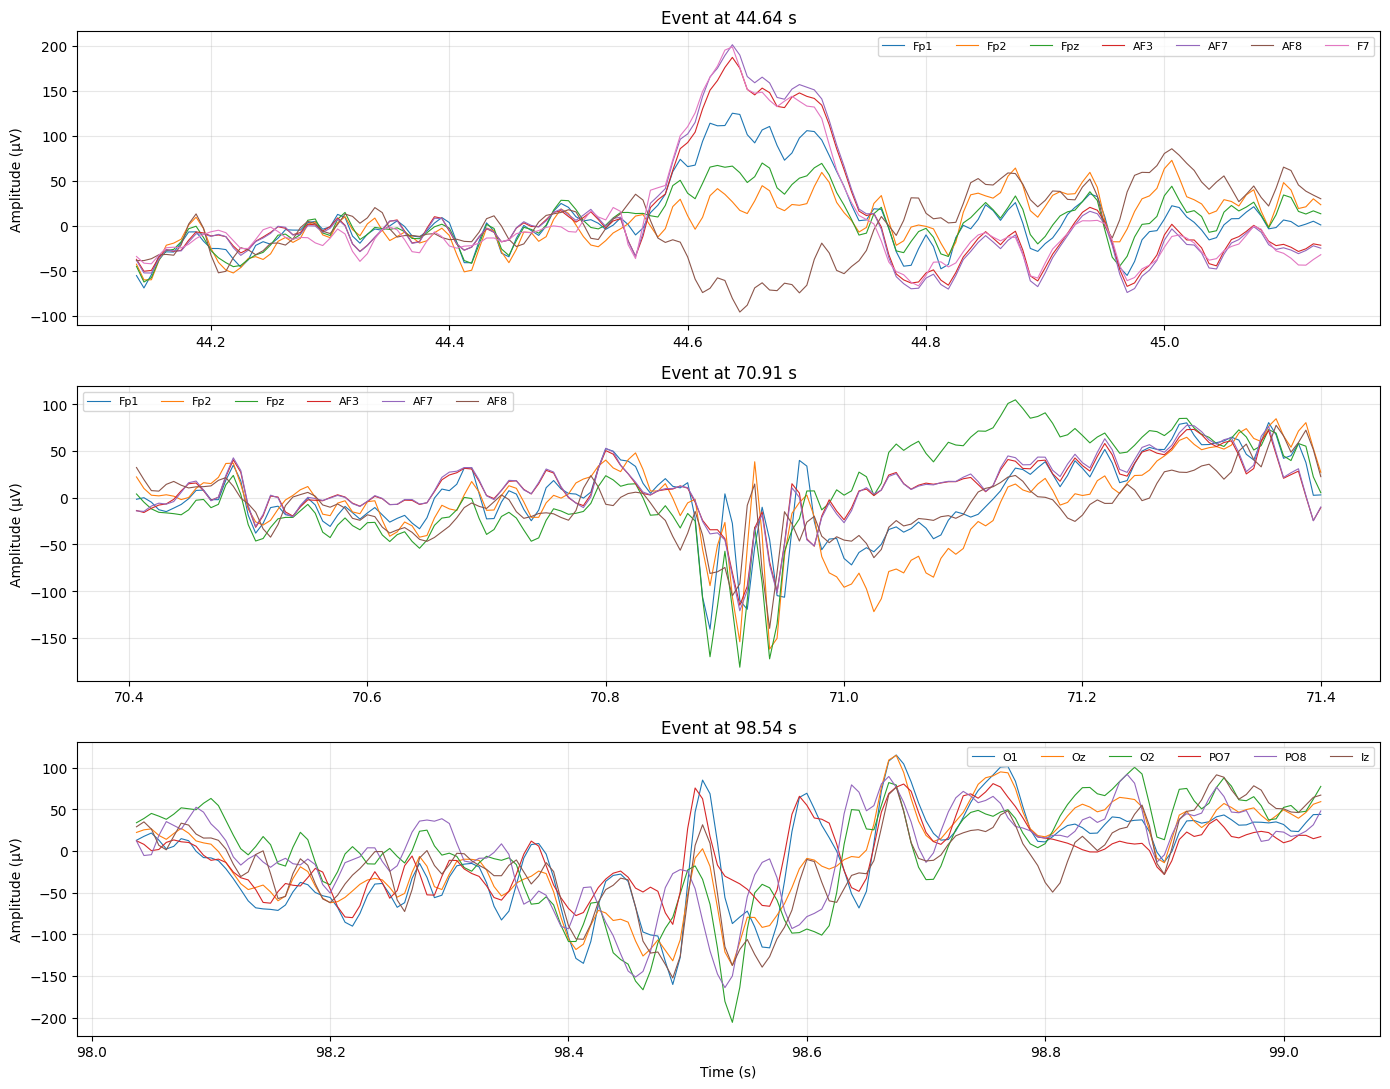

In [7]:
import matplotlib.pyplot as plt
import numpy as np

events = [
    {
        "time": 44.64,
        "channels": ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8", "F7"],
        "title": "Event at 44.64 s"
    },
    {
        "time": 70.91,
        "channels": ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"],
        "title": "Event at 70.91 s"
    },
    {
        "time": 98.54,
        "channels": ["O1", "Oz", "O2", "PO7", "PO8", "Iz"],
        "title": "Event at 98.54 s"
    }
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11)
)

for ax, event in zip(axes, events):

    center = event["time"]
    start = int((center - 0.5) * raw.info["sfreq"])
    end = int((center + 0.5) * raw.info["sfreq"])

    times = raw.times[start:end]

    for ch in event["channels"]:
        data = raw.get_data(
            picks=[ch],
            start=start,
            stop=end
        )[0] * 1e6

        ax.plot(times, data, label=ch, linewidth=0.8)

    ax.set_title(event["title"])
    ax.set_ylabel("Amplitude (µV)")
    ax.grid(alpha=0.3)
    ax.legend(ncol=7, fontsize=8)

axes[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import pandas as pd

# 统计每个通道超过100 µV的采样点比例
threshold = 100

extreme_ratio = (
    np.abs(eeg_data) > threshold
).mean(axis=1) * 100

extreme_report = pd.DataFrame({
    "通道": raw.copy().pick("eeg").ch_names,
    "超过100µV的采样点比例(%)": extreme_ratio
})

extreme_report = extreme_report.sort_values(
    "超过100µV的采样点比例(%)",
    ascending=False
)

display(extreme_report.head(15).round(3))

,通道,超过100µV的采样点比例(%)
62,O2,0.405
37,F8,0.400
63,Iz,0.360
24,AF7,0.345
61,Oz,0.290
25,AF3,0.285
21,Fp1,0.275
43,T10,0.270
60,O1,0.265
59,PO8,0.250


In [9]:
import pandas as pd
import numpy as np
import os
# 合并逐通道质量指标
final_quality = channel_quality.merge(
    extreme_report,
    on="通道",
    how="left"
)

# 添加初步筛查标签
final_quality["筛查提示"] = np.where(
    final_quality["超过100µV的采样点比例(%)"] >= 0.3,
    "需要复核",
    "暂未发现明显振幅异常"
)

final_quality = final_quality.sort_values(
    "超过100µV的采样点比例(%)",
    ascending=False
)

display(final_quality.round(3))

# 定位 Project 04 根目录
project_dir = os.path.abspath("..")

# 确保 results 目录存在
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# 保存质量报告
output_path = os.path.join(
    results_dir,
    "EEG_channel_quality_report.csv"
)

final_quality.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("质量报告保存成功：")
print(output_path)
print("文件存在：", os.path.exists(output_path))

,通道,平均绝对振幅(µV),最大振幅(µV),标准差(µV),超过100µV的采样点比例(%),筛查提示
0,O2,26.287,205.642,33.378,0.405,需要复核
14,F8,22.568,142.333,29.192,0.400,需要复核
10,Iz,23.587,152.425,30.112,0.360,需要复核
1,AF7,21.582,201.442,28.119,0.345,需要复核
12,Oz,22.511,145.852,28.800,0.290,暂未发现明显振幅异常
...,...,...,...,...,...,...
59,CP1,12.947,80.893,16.369,0.000,暂未发现明显振幅异常
60,P5,15.533,79.098,19.639,0.000,暂未发现明显振幅异常
61,CP5,13.077,78.083,16.633,0.000,暂未发现明显振幅异常
62,P3,15.348,77.660,19.380,0.000,暂未发现明显振幅异常


质量报告保存成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\results\EEG_channel_quality_report.csv
文件存在： True


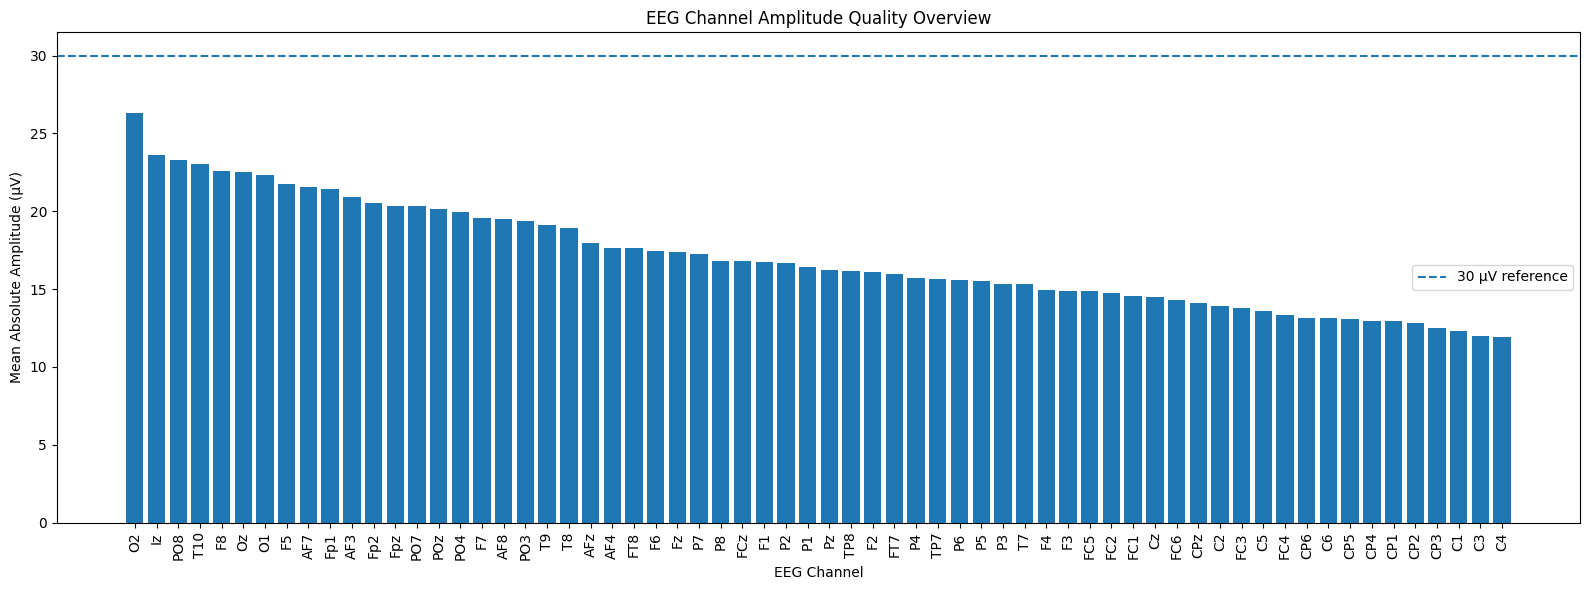

图表保存成功： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\figures\EEG_channel_amplitude_overview.png


In [10]:
import matplotlib.pyplot as plt
import os

plot_data = final_quality.sort_values(
    "平均绝对振幅(µV)",
    ascending=False
)

plt.figure(figsize=(16, 6))

plt.bar(
    plot_data["通道"],
    plot_data["平均绝对振幅(µV)"]
)

plt.axhline(
    30,
    linestyle="--",
    label="30 µV reference"
)

plt.xticks(rotation=90)
plt.ylabel("Mean Absolute Amplitude (µV)")
plt.xlabel("EEG Channel")
plt.title("EEG Channel Amplitude Quality Overview")

plt.legend()
plt.tight_layout()

fig_path = os.path.join(
    results_dir.replace("results", "figures"),
    "EEG_channel_amplitude_overview.png"
)

os.makedirs(os.path.dirname(fig_path), exist_ok=True)

plt.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("图表保存成功：", fig_path)

In [11]:
import mne
import pandas as pd
import numpy as np

# 定义频段
bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

# 计算 PSD
spectrum = raw.compute_psd(
    method="welch",
    fmin=1,
    fmax=45,
    n_fft=512,
    n_overlap=256,
    verbose=False
)

psds, freqs = spectrum.get_data(return_freqs=True)

# 提取各频段平均功率
band_results = []

for ch_index, ch_name in enumerate(raw.ch_names):

    row = {"通道": ch_name}

    for band, (low, high) in bands.items():

        mask = (freqs >= low) & (freqs < high)

        row[band] = np.mean(
            psds[ch_index, mask]
        )

    band_results.append(row)

band_power_df = pd.DataFrame(band_results)

display(band_power_df.head(10).round(12))

,通道,Delta,Theta,Alpha,Beta,Gamma
0,FC5,4.500000e-11,1.100000e-11,1.000000e-11,3.000000e-12,1.000000e-12
1,FC3,3.000000e-11,9.000000e-12,1.400000e-11,4.000000e-12,1.000000e-12
2,FC1,3.600000e-11,1.300000e-11,1.200000e-11,4.000000e-12,1.000000e-12
3,FCz,5.100000e-11,1.900000e-11,1.200000e-11,4.000000e-12,1.000000e-12
4,FC2,3.700000e-11,1.300000e-11,1.200000e-11,4.000000e-12,1.000000e-12
5,FC4,2.900000e-11,9.000000e-12,1.300000e-11,3.000000e-12,1.000000e-12
6,FC6,4.400000e-11,1.100000e-11,9.000000e-12,3.000000e-12,1.000000e-12
7,C5,3.900000e-11,9.000000e-12,8.000000e-12,3.000000e-12,1.000000e-12
8,C3,2.300000e-11,8.000000e-12,1.200000e-11,2.000000e-12,1.000000e-12
9,C1,3.200000e-11,1.000000e-11,7.000000e-12,2.000000e-12,1.000000e-12


In [12]:
import pandas as pd
import numpy as np

# 复制绝对功率表
relative_power_df = band_power_df.copy()

# 计算每个通道五个频段的总功率
total_power = band_power_df[
    ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
].sum(axis=1)

# 计算相对功率
for band in ["Delta", "Theta", "Alpha", "Beta", "Gamma"]:

    relative_power_df[band] = (
        band_power_df[band] / total_power
    )

display(relative_power_df.head(10).round(4))

,通道,Delta,Theta,Alpha,Beta,Gamma
0,FC5,0.6442,0.1558,0.1363,0.0482,0.0154
1,FC3,0.5228,0.1614,0.2396,0.0621,0.0141
2,FC1,0.5564,0.1939,0.1795,0.0570,0.0132
3,FCz,0.5842,0.2148,0.1399,0.0488,0.0122
4,FC2,0.5533,0.1966,0.1837,0.0542,0.0122
5,FC4,0.5257,0.1690,0.2321,0.0601,0.0131
6,FC6,0.6448,0.1648,0.1308,0.0468,0.0129
7,C5,0.6487,0.1573,0.1400,0.0415,0.0124
8,C3,0.5027,0.1708,0.2566,0.0537,0.0162
9,C1,0.6192,0.1962,0.1319,0.0399,0.0128


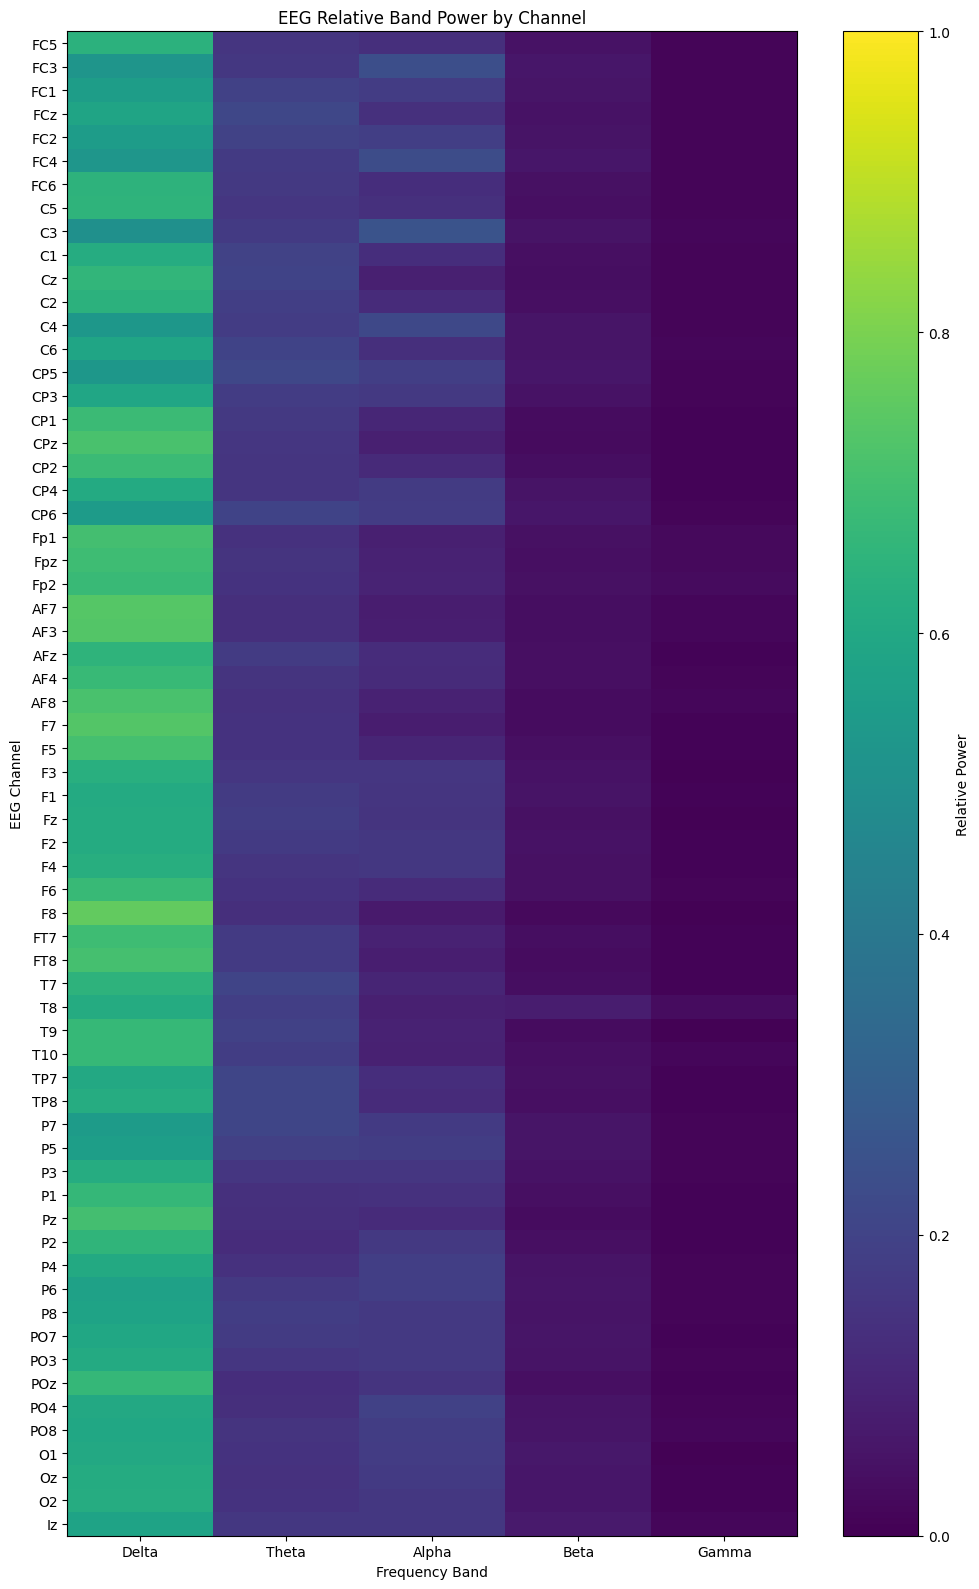

绝对功率： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\results\EEG_band_power_absolute.csv
相对功率： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\results\EEG_band_power_relative.csv
频段热图： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\figures\EEG_relative_band_power_heatmap.png


In [13]:
import os
import matplotlib.pyplot as plt

# 确保输出目录存在
os.makedirs(results_dir, exist_ok=True)

figures_dir = os.path.join(project_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

# 保存绝对功率和相对功率
absolute_path = os.path.join(
    results_dir, "EEG_band_power_absolute.csv"
)

relative_path = os.path.join(
    results_dir, "EEG_band_power_relative.csv"
)

band_power_df.to_csv(
    absolute_path, index=False, encoding="utf-8-sig"
)

relative_power_df.to_csv(
    relative_path, index=False, encoding="utf-8-sig"
)

# 准备热图数据
bands_list = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]

heatmap_data = relative_power_df.set_index("通道")[bands_list]

# 使用 Matplotlib 绘制热图
plt.figure(figsize=(10, 16))

plt.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Relative Power")

plt.xticks(
    range(len(bands_list)),
    bands_list
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("EEG Relative Band Power by Channel")
plt.xlabel("Frequency Band")
plt.ylabel("EEG Channel")

plt.tight_layout()

heatmap_path = os.path.join(
    figures_dir,
    "EEG_relative_band_power_heatmap.png"
)

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("绝对功率：", absolute_path)
print("相对功率：", relative_path)
print("频段热图：", heatmap_path)

In [14]:
import os

files_to_check = [
    os.path.join(results_dir, "EEG_channel_quality_report.csv"),
    os.path.join(results_dir, "EEG_band_power_absolute.csv"),
    os.path.join(results_dir, "EEG_band_power_relative.csv"),
    os.path.join(figures_dir, "EEG_channel_amplitude_overview.png"),
    os.path.join(figures_dir, "EEG_relative_band_power_heatmap.png")
]

for path in files_to_check:
    print(
        "✓" if os.path.exists(path) else "✗",
        os.path.basename(path),
        f"{os.path.getsize(path) / 1024:.1f} KB"
        if os.path.exists(path) else "文件不存在"
    )

✓ EEG_channel_quality_report.csv 6.1 KB
✓ EEG_band_power_absolute.csv 7.3 KB
✓ EEG_band_power_relative.csv 6.5 KB
✓ EEG_channel_amplitude_overview.png 141.5 KB
✓ EEG_relative_band_power_heatmap.png 229.4 KB


In [15]:
import os
from datetime import datetime

report_dir = os.path.join(project_dir, "reports")
os.makedirs(report_dir, exist_ok=True)

# 统计需要复核的通道
review_channels = final_quality[
    final_quality["筛查提示"] == "需要复核"
]["通道"].tolist()

# 计算各频段平均相对功率
bands_list = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]

mean_relative_power = (
    relative_power_df[bands_list].mean()
)

# 生成 HTML 报告
html = f"""
<!DOCTYPE html>
<html lang="zh-CN">
<head>
<meta charset="UTF-8">
<title>EEG 自动化分析报告</title>
<style>
body {{
    font-family: Arial, sans-serif;
    max-width: 1000px;
    margin: 40px auto;
    line-height: 1.7;
    color: #222;
}}
h1, h2 {{ color: #234; }}
table {{
    border-collapse: collapse;
    width: 100%;
}}
th, td {{
    border: 1px solid #ddd;
    padding: 9px;
    text-align: left;
}}
th {{ background: #edf2f7; }}
img {{
    max-width: 100%;
    height: auto;
}}
.note {{
    background: #f3f5f7;
    padding: 12px;
}}
</style>
</head>
<body>

<h1>EEG 自动化分析报告</h1>
<p>生成时间：{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}</p>

<h2>1. 数据基本信息</h2>
<table>
<tr><th>指标</th><th>结果</th></tr>
<tr><td>EEG通道数量</td><td>{len(raw.ch_names)}</td></tr>
<tr><td>采样率</td><td>{raw.info["sfreq"]} Hz</td></tr>
<tr><td>数据时长</td><td>{raw.times[-1]:.2f} 秒</td></tr>
<tr><td>采样点数</td><td>{raw.n_times}</td></tr>
</table>

<h2>2. 数据质量检查</h2>
<table>
<tr><th>指标</th><th>结果</th></tr>
<tr><td>NaN数量</td><td>{np.isnan(eeg_data).sum()}</td></tr>
<tr><td>Inf数量</td><td>{np.isinf(eeg_data).sum()}</td></tr>
<tr><td>最大绝对振幅</td><td>{np.max(np.abs(eeg_data)):.2f} µV</td></tr>
<tr><td>平均绝对振幅</td><td>{np.mean(np.abs(eeg_data)):.2f} µV</td></tr>
</table>

<h2>3. 需要复核的通道</h2>
<p>{", ".join(review_channels) if review_channels else "暂无"}</p>

<p class="note">
本报告中的通道提示属于振幅筛查结果，不等同于坏通道诊断。
超过100 µV的阈值仅用于本次探索性检查。
</p>

<h2>4. 五大频段平均相对功率</h2>
<table>
<tr><th>频段</th><th>平均相对功率</th></tr>
{''.join(
    f"<tr><td>{band}</td><td>{value:.4f}</td></tr>"
    for band, value in mean_relative_power.items()
)}
</table>

<h2>5. 通道振幅分布图</h2>
<img src="../figures/EEG_channel_amplitude_overview.png">

<h2>6. 五大频段相对功率热图</h2>
<img src="../figures/EEG_relative_band_power_heatmap.png">

<h2>7. 分析局限</h2>
<p>
本报告基于已经经过前序处理的EEG数据。
频段功率反映所选频率范围内的频谱特征，
不能单独用于诊断疾病或推断意识状态。
通道异常提示需要结合原始波形、空间分布和实验背景进一步复核。
</p>

</body>
</html>
"""

report_path = os.path.join(
    report_dir,
    "EEG_Automated_Analysis_Report.html"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(html)

print("HTML报告生成成功：")
print(report_path)
print("文件大小：", round(os.path.getsize(report_path) / 1024, 2), "KB")

HTML报告生成成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\reports\EEG_Automated_Analysis_Report.html
文件大小： 2.25 KB


In [16]:
import os

print("===== Project 04 报告文件检查 =====")

print("HTML报告：", os.path.exists(report_path))

print("\n报告引用的图片：")

image_paths = [
    os.path.join(figures_dir, "EEG_channel_amplitude_overview.png"),
    os.path.join(figures_dir, "EEG_relative_band_power_heatmap.png")
]

for path in image_paths:
    print(
        os.path.basename(path),
        "存在" if os.path.exists(path) else "不存在"
    )

print("\n报告文件大小：",
      round(os.path.getsize(report_path) / 1024, 2), "KB")

===== Project 04 报告文件检查 =====
HTML报告： True

报告引用的图片：
EEG_channel_amplitude_overview.png 存在
EEG_relative_band_power_heatmap.png 存在

报告文件大小： 2.25 KB


In [17]:
import os
import base64

# 读取原来的 HTML 报告
with open(report_path, "r", encoding="utf-8") as f:
    html = f.read()

# 将图片转换为 Base64 并嵌入 HTML
image_files = {
    "../figures/EEG_channel_amplitude_overview.png":
        os.path.join(figures_dir, "EEG_channel_amplitude_overview.png"),

    "../figures/EEG_relative_band_power_heatmap.png":
        os.path.join(figures_dir, "EEG_relative_band_power_heatmap.png")
}

for old_path, image_path in image_files.items():

    if not os.path.exists(image_path):
        raise FileNotFoundError(image_path)

    with open(image_path, "rb") as f:
        image_data = base64.b64encode(f.read()).decode("utf-8")

    new_path = "data:image/png;base64," + image_data

    html = html.replace(old_path, new_path)

# 覆盖保存 HTML 报告
with open(report_path, "w", encoding="utf-8") as f:
    f.write(html)

print("图片嵌入成功")
print("报告大小：", round(os.path.getsize(report_path) / 1024, 2), "KB")
print("报告路径：", report_path)

图片嵌入成功
报告大小： 496.68 KB
报告路径： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\reports\EEG_Automated_Analysis_Report.html


In [18]:
readme_content = """# Project 04 — Automated EEG Analysis Report

## 1. 项目简介

本项目基于经过预处理和 ICA 伪迹清理的 EEG 数据，
建立自动化 EEG 分析流程。

主要功能：
- EEG 数据质量检查
- 逐通道振幅统计
- 五大频段 PSD 特征提取
- 相对频段功率计算
- EEG 数据可视化
- 自动生成 HTML 分析报告

## 2. 分析环境

- Python
- MNE
- NumPy
- Pandas
- Matplotlib
- Jupyter Notebook

## 3. 分析流程

1. 读取 Project 03 输出的 ICA 清理后 EEG 数据
2. 检查数据维度、采样率、NaN 和 Inf
3. 计算逐通道振幅统计指标
4. 使用 Welch 方法计算功率谱密度（PSD）
5. 提取 Delta、Theta、Alpha、Beta、Gamma 五个频段特征
6. 生成相对功率热图和通道振幅分布图
7. 导出 CSV 数据和 HTML 分析报告

## 4. 频段定义

| 频段 | 范围 |
|---|---|
| Delta | 1–4 Hz |
| Theta | 4–8 Hz |
| Alpha | 8–13 Hz |
| Beta | 13–30 Hz |
| Gamma | 30–45 Hz |

本项目使用各频段内的平均 PSD 作为特征，
并在选定的五个频段之间计算相对功率。
该指标不等同于频段积分功率。

## 5. 项目输出

- `results/EEG_channel_quality_report.csv`
- `results/EEG_band_power_absolute.csv`
- `results/EEG_band_power_relative.csv`
- `figures/EEG_channel_amplitude_overview.png`
- `figures/EEG_relative_band_power_heatmap.png`
- `reports/EEG_Automated_Analysis_Report.html`

## 6. 运行方法

打开 `notebooks/04_Automated_EEG_Analysis_Report.ipynb`，
按顺序运行所有代码单元格。

输入数据为 Project 03 生成的 ICA 清理后 EEG 文件。

## 7. 分析局限

- 本项目使用的数据已经经过预处理和 ICA 清理，并非原始数据全流程处理。
- 振幅阈值仅用于探索性筛查，不能单独作为坏通道判定依据。
- 频段特征不能单独用于判断意识状态或作出临床诊断。
- 分析结果需要结合实验设计、受试者状态和其他证据解释。

## 8. 数据说明

公开项目时，请确保 EEG 数据具有公开授权。
未获得授权时，不上传原始或可识别受试者的数据文件。
"""

readme_path = os.path.join(project_dir, "README.md")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README 创建成功：")
print(readme_path)

README 创建成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report\README.md


In [19]:
import os

print("===== Project 04 最终目录检查 =====")

for folder in ["notebooks", "src", "results", "figures", "reports"]:
    folder_path = os.path.join(project_dir, folder)

    print(f"\n[{folder}]")

    if os.path.exists(folder_path):
        files = [
            f for f in os.listdir(folder_path)
            if os.path.isfile(os.path.join(folder_path, f))
        ]

        if files:
            for filename in files:
                print(" ✓", filename)
        else:
            print(" （暂无文件）")
    else:
        print(" ✗ 文件夹不存在")

print("\nREADME 存在：", os.path.exists(readme_path))

===== Project 04 最终目录检查 =====

[notebooks]
 ✓ 04_Automated_EEG_Analysis_Report.ipynb

[src]
 （暂无文件）

[results]
 ✓ EEG_band_power_absolute.csv
 ✓ EEG_band_power_relative.csv
 ✓ EEG_channel_quality_report.csv

[figures]
 ✓ EEG_channel_amplitude_overview.png
 ✓ EEG_relative_band_power_heatmap.png

[reports]
 ✓ EEG_Automated_Analysis_Report.html

README 存在： True


In [20]:
import os

portfolio_dir = os.path.dirname(project_dir)
gitignore_path = os.path.join(portfolio_dir, ".gitignore")

print("===== GitHub 仓库检查 =====")
print("仓库目录：", portfolio_dir)
print(".gitignore 是否存在：", os.path.exists(gitignore_path))

if os.path.exists(gitignore_path):
    print("\n===== 当前 .gitignore 内容 =====")
    with open(gitignore_path, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("当前没有 .gitignore 文件")

===== GitHub 仓库检查 =====
仓库目录： C:\Users\Administrator\EEG-Analysis-Portfolio
.gitignore 是否存在： False
当前没有 .gitignore 文件


In [21]:
import os

gitignore_content = """# EEG data files - do not upload without authorization
*.fif
*.edf
*.bdf
*.vhdr
*.vmrk
*.eeg
*.set
*.fdt
*.gdf
*.cnt

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Temporary files
*.tmp
*.log
*.bak
"""

gitignore_path = os.path.join(portfolio_dir, ".gitignore")

with open(gitignore_path, "w", encoding="utf-8") as f:
    f.write(gitignore_content)

print(".gitignore 创建成功：")
print(gitignore_path)

with open(gitignore_path, "r", encoding="utf-8") as f:
    print("\n===== 文件内容 =====")
    print(f.read())

.gitignore 创建成功：
C:\Users\Administrator\EEG-Analysis-Portfolio\.gitignore

===== 文件内容 =====
# EEG data files - do not upload without authorization
*.fif
*.edf
*.bdf
*.vhdr
*.vmrk
*.eeg
*.set
*.fdt
*.gdf
*.cnt

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Temporary files
*.tmp
*.log
*.bak



In [22]:
import os

print("===== EEG Portfolio 文件检查 =====")

for root, dirs, files in os.walk(portfolio_dir):
    # 跳过缓存目录
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__", ".git"]
    ]

    relative_path = os.path.relpath(root, portfolio_dir)

    print(f"\n[{relative_path}]")

    for filename in files:
        if filename.endswith(".ipynb") or filename.endswith((
            ".py", ".md", ".html", ".csv", ".png", ".pdf",
            ".fif", ".edf", ".bdf"
        )):
            print(" -", filename)

===== EEG Portfolio 文件检查 =====

[.]

[Project_03_ICA_Artifact_Removal]
 - README.md

[Project_03_ICA_Artifact_Removal\figures]

[Project_03_ICA_Artifact_Removal\figures\ICA]
 - ICA000_before_after_comparison.pdf
 - ICA000_before_after_comparison.png

[Project_03_ICA_Artifact_Removal\notebooks]
 - 03_EEG_QualityControl_ICA.ipynb

[Project_03_ICA_Artifact_Removal\reports]
 - ICA_Analysis_Report.md

[Project_03_ICA_Artifact_Removal\results]
 - EEG_ICA_cleaned_raw.fif
 - EEG_ICA_model.fif

[Project_04_Automated_EEG_Report]
 - README.md

[Project_04_Automated_EEG_Report\figures]
 - EEG_channel_amplitude_overview.png
 - EEG_relative_band_power_heatmap.png

[Project_04_Automated_EEG_Report\notebooks]
 - 04_Automated_EEG_Analysis_Report.ipynb
 - 04_Automated_EEG_Analysis_Report.ipynb.ipynb

[Project_04_Automated_EEG_Report\notebooks\EEG-Analysis-Portfolio]

[Project_04_Automated_EEG_Report\notebooks\EEG-Analysis-Portfolio\Project_04_Automated_EEG_Report]

[Project_04_Automated_EEG_Report\noteb

In [2]:
import os
import pandas as pd

# 重新定义作品集根目录
portfolio_dir = r"C:\Users\Administrator\EEG-Analysis-Portfolio"

# Project 04 的结果目录
results_dir = os.path.join(
    portfolio_dir,
    "Project_04_Automated_EEG_Report",
    "results"
)

csv_files = [
    "EEG_channel_quality_report.csv",
    "EEG_band_power_absolute.csv",
    "EEG_band_power_relative.csv"
]

for filename in csv_files:
    path = os.path.join(results_dir, filename)

    print("\n" + "=" * 55)
    print("文件：", filename)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("数据维度：", df.shape)
        print("字段：", list(df.columns))
        print("\n前3行：")
        print(df.head(3).to_string(index=False))
    else:
        print("文件不存在：", path)


文件： EEG_channel_quality_report.csv
数据维度： (64, 6)
字段： ['通道', '平均绝对振幅(µV)', '最大振幅(µV)', '标准差(µV)', '超过100µV的采样点比例(%)', '筛查提示']

前3行：
通道  平均绝对振幅(µV)   最大振幅(µV)   标准差(µV)  超过100µV的采样点比例(%) 筛查提示
O2   26.287075 205.642442 33.378450             0.405 需要复核
F8   22.567670 142.333272 29.192175             0.400 需要复核
Iz   23.587146 152.424778 30.112244             0.360 需要复核

文件： EEG_band_power_absolute.csv
数据维度： (64, 6)
字段： ['通道', 'Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']

前3行：
 通道        Delta        Theta        Alpha         Beta        Gamma
FC5 4.527711e-11 1.094868e-11 9.581821e-12 3.390845e-12 1.081174e-12
FC3 2.996877e-11 9.250839e-12 1.373218e-11 3.561883e-12 8.056226e-13
FC1 3.601641e-11 1.255323e-11 1.162122e-11 3.691847e-12 8.513892e-13

文件： EEG_band_power_relative.csv
数据维度： (64, 6)
字段： ['通道', 'Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']

前3行：
 通道    Delta    Theta    Alpha     Beta    Gamma
FC5 0.644242 0.155787 0.136339 0.048248 0.015384
FC3 0.522839 0.161391 0.239573 0.062141 0.

In [3]:
import os

gitignore_path = os.path.join(
    portfolio_dir,
    ".gitignore"
)

print("===== GitHub 上传安全检查 =====")

with open(gitignore_path, "r", encoding="utf-8") as f:
    rules = f.read()

print(rules)

print("\nFIF 忽略规则存在：", "*.fif" in rules)
print("EDF 忽略规则存在：", "*.edf" in rules)
print("Jupyter 缓存忽略规则存在：", ".ipynb_checkpoints/" in rules)

===== GitHub 上传安全检查 =====
# EEG data files - do not upload without authorization
*.fif
*.edf
*.bdf
*.vhdr
*.vmrk
*.eeg
*.set
*.fdt
*.gdf
*.cnt

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Temporary files
*.tmp
*.log
*.bak


FIF 忽略规则存在： True
EDF 忽略规则存在： True
Jupyter 缓存忽略规则存在： True
